# Data Preprocessing – California Housing Dataset

**Project:** House Price Prediction Using Machine Learning  
**Dataset:** California Housing Prices (`housing.csv`)  
**Responsible section:** Data Preprocessing

## Objective
This notebook documents the data preprocessing workflow: missing-value analysis and treatment, outlier detection using two methods, outlier treatment, feature scaling, and categorical encoding.

> **Important:** The exploratory analysis below is used to understand the dataset. For the final model-ready data, the train-test split is performed before fitting imputation, capping, scaling, and encoding parameters. This helps prevent data leakage.


## 1. Load the Dataset

Upload `housing.csv` to the Colab session (or update the file path if it is stored elsewhere).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/housing.csv')

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


## 2. Missing Values Analysis

Missing values can reduce the amount of usable information and may cause some machine-learning algorithms to fail. We calculate both the number and percentage of missing values for every attribute.

In [2]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

display(missing_summary.round(3))

,Missing Values,Missing Percentage (%)
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,207,1.003
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000


### 2.1 Missing Values Treatment

The dataset contains 207 missing values in `total_bedrooms` (approximately 1.00%). We choose median imputation because the median is less affected by extreme values than the mean.

For exploratory analysis and outlier summaries, a separate copy is filled below. The final model preprocessing later estimates the median from the training set only.

In [3]:
bedrooms_median_eda = df['total_bedrooms'].median()

df_eda = df.copy()
df_eda['total_bedrooms'] = df_eda['total_bedrooms'].fillna(bedrooms_median_eda)

print("Median used for exploratory copy:", bedrooms_median_eda)
print("Missing values after exploratory imputation:", df_eda.isnull().sum().sum())

Median used for exploratory copy: 435.0
Missing values after exploratory imputation: 0


## 3. Outlier Detection

An outlier is an observation that lies unusually far from most other observations. Outliers may represent errors, but they can also be valid observations, so they should not automatically be deleted.

We use two detection methods: **IQR** and **Z-Score**.

### 3.1 Interquartile Range (IQR)

The IQR method uses the first quartile (Q1) and third quartile (Q3):

- IQR = Q3 − Q1
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Values outside these bounds are flagged as potential outliers.

In [4]:
iqr_columns = [
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income',
    'median_house_value'
]

iqr_results = []

for column in iqr_columns:
    q1 = df_eda[column].quantile(0.25)
    q3 = df_eda[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_eda[column] < lower_bound) |
        (df_eda[column] > upper_bound)
    )

    iqr_results.append({
        'Feature': column,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': int(outlier_mask.sum()),
        'Outliers Percentage (%)': outlier_mask.mean() * 100
    })

iqr_table = pd.DataFrame(iqr_results)
display(iqr_table.round(3))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count,Outliers Percentage (%)
0,housing_median_age,18.000,37.000,19.00,-10.500,65.500,0,0.000
1,total_rooms,1447.750,3148.000,1700.25,-1102.625,5698.375,1287,6.235
2,total_bedrooms,297.000,643.250,346.25,-222.375,1162.625,1306,6.328
3,population,787.000,1725.000,938.00,-620.000,3132.000,1196,5.795
4,households,280.000,605.000,325.00,-207.500,1092.500,1220,5.911
5,median_income,2.563,4.743,2.18,-0.706,8.013,681,3.299
6,median_house_value,119600.000,264725.000,145125.00,-98087.500,482412.500,1071,5.189


### 3.2 Z-Score Method

The Z-Score measures how many standard deviations an observation is from the mean:

**Z = (x − mean) / standard deviation**

We use the common threshold |Z| > 3 to flag potential outliers. Z-Score is applied to the same five predictor variables used in our comparison.

In [5]:
from scipy.stats import zscore

zscore_columns = [
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income'
]

zscore_results = []

for column in zscore_columns:
    scores = zscore(df_eda[column])
    outlier_mask = np.abs(scores) > 3

    zscore_results.append({
        'Feature': column,
        'Outliers Count': int(outlier_mask.sum()),
        'Outliers Percentage (%)': outlier_mask.mean() * 100
    })

zscore_table = pd.DataFrame(zscore_results)
display(zscore_table.round(3))

,Feature,Outliers Count,Outliers Percentage (%)
0,total_rooms,373,1.807
1,total_bedrooms,375,1.817
2,population,342,1.657
3,households,363,1.759
4,median_income,345,1.672


### 3.3 Comparison of IQR and Z-Score

The two methods identify different numbers of potential outliers because they use different statistical rules. In our results, IQR identifies more potential outliers than Z-Score for each of the five compared features. This is consistent with the right-skewed distributions observed in several variables.

The counts are per feature; the same dataset row may be flagged in more than one feature, so these counts should not be added to estimate unique outlier rows.

In [6]:
comparison = iqr_table[iqr_table['Feature'].isin(zscore_columns)][
    ['Feature', 'Outliers Count', 'Outliers Percentage (%)']
].rename(columns={
    'Outliers Count': 'IQR Count',
    'Outliers Percentage (%)': 'IQR Percentage (%)'
})

comparison = comparison.merge(
    zscore_table.rename(columns={
        'Outliers Count': 'Z-Score Count',
        'Outliers Percentage (%)': 'Z-Score Percentage (%)'
    }),
    on='Feature'
)

display(comparison.round(3))

,Feature,IQR Count,IQR Percentage (%),Z-Score Count,Z-Score Percentage (%)
0,total_rooms,1287,6.235,373,1.807
1,total_bedrooms,1306,6.328,375,1.817
2,population,1196,5.795,342,1.657
3,households,1220,5.911,363,1.759
4,median_income,681,3.299,345,1.672


## 4. Boxplots Before Outlier Treatment

The boxplots visually show the spread of each selected numerical feature and potential extreme observations.

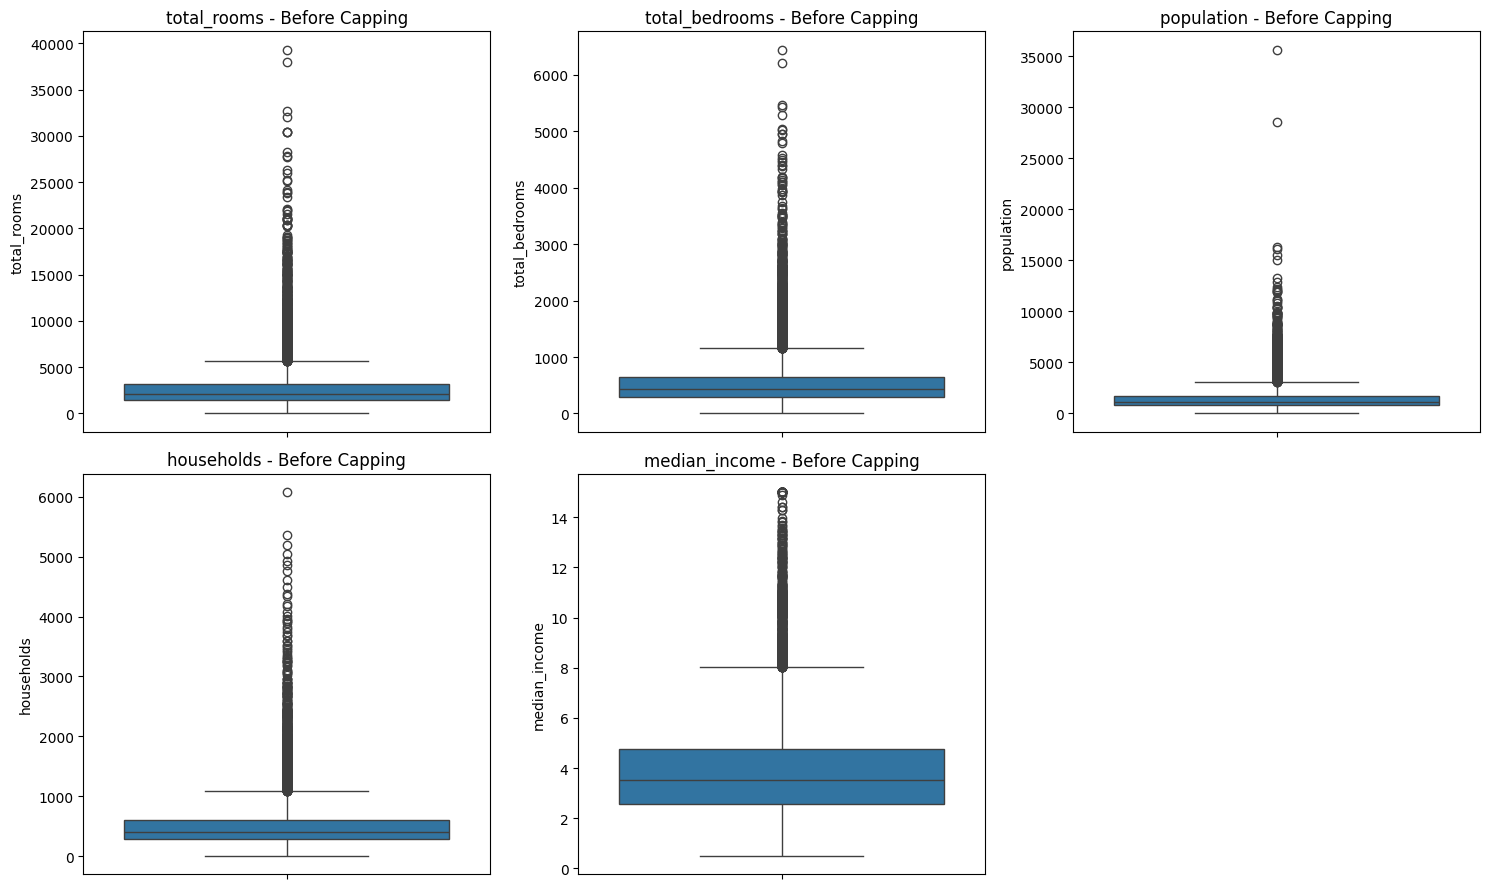

In [7]:
boxplot_columns = [
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, column in enumerate(boxplot_columns):
    sns.boxplot(y=df_eda[column], ax=axes[i])
    axes[i].set_title(f'{column} - Before Capping')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## 5. Outlier Treatment: IQR Capping

We use IQR capping for selected predictor variables rather than deleting complete rows. Values below the lower bound or above the upper bound are replaced with the corresponding bound.

This choice preserves the number of observations while limiting the influence of extreme predictor values. We do **not** cap `median_house_value`, because it is the target variable, or the geographic coordinates. We also leave `housing_median_age` unchanged because IQR did not flag outliers in that feature.

The following copy is used only to demonstrate the before-and-after effect on the full exploratory dataset. The final model-ready capping is recalculated using the training set only in Section 7.

In [8]:
df_eda_capped = df_eda.copy()

capping_columns = [
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income'
]

eda_capping_results = []

for column in capping_columns:
    q1 = df_eda_capped[column].quantile(0.25)
    q3 = df_eda_capped[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    before = (
        (df_eda_capped[column] < lower) |
        (df_eda_capped[column] > upper)
    ).sum()

    df_eda_capped[column] = df_eda_capped[column].clip(
        lower=lower,
        upper=upper
    )

    after = (
        (df_eda_capped[column] < lower) |
        (df_eda_capped[column] > upper)
    ).sum()

    eda_capping_results.append({
        'Feature': column,
        'Outliers Before': int(before),
        'Outliers After': int(after),
        'Lower Cap': lower,
        'Upper Cap': upper
    })

eda_capping_table = pd.DataFrame(eda_capping_results)
display(eda_capping_table.round(3))

,Feature,Outliers Before,Outliers After,Lower Cap,Upper Cap
0,total_rooms,1287,0,-1102.625,5698.375
1,total_bedrooms,1306,0,-222.375,1162.625
2,population,1196,0,-620.000,3132.000
3,households,1220,0,-207.500,1092.500
4,median_income,681,0,-0.706,8.013


### 5.1 Boxplots After Capping

The updated boxplots show that values beyond the selected IQR limits have been capped. The original number of rows is preserved.

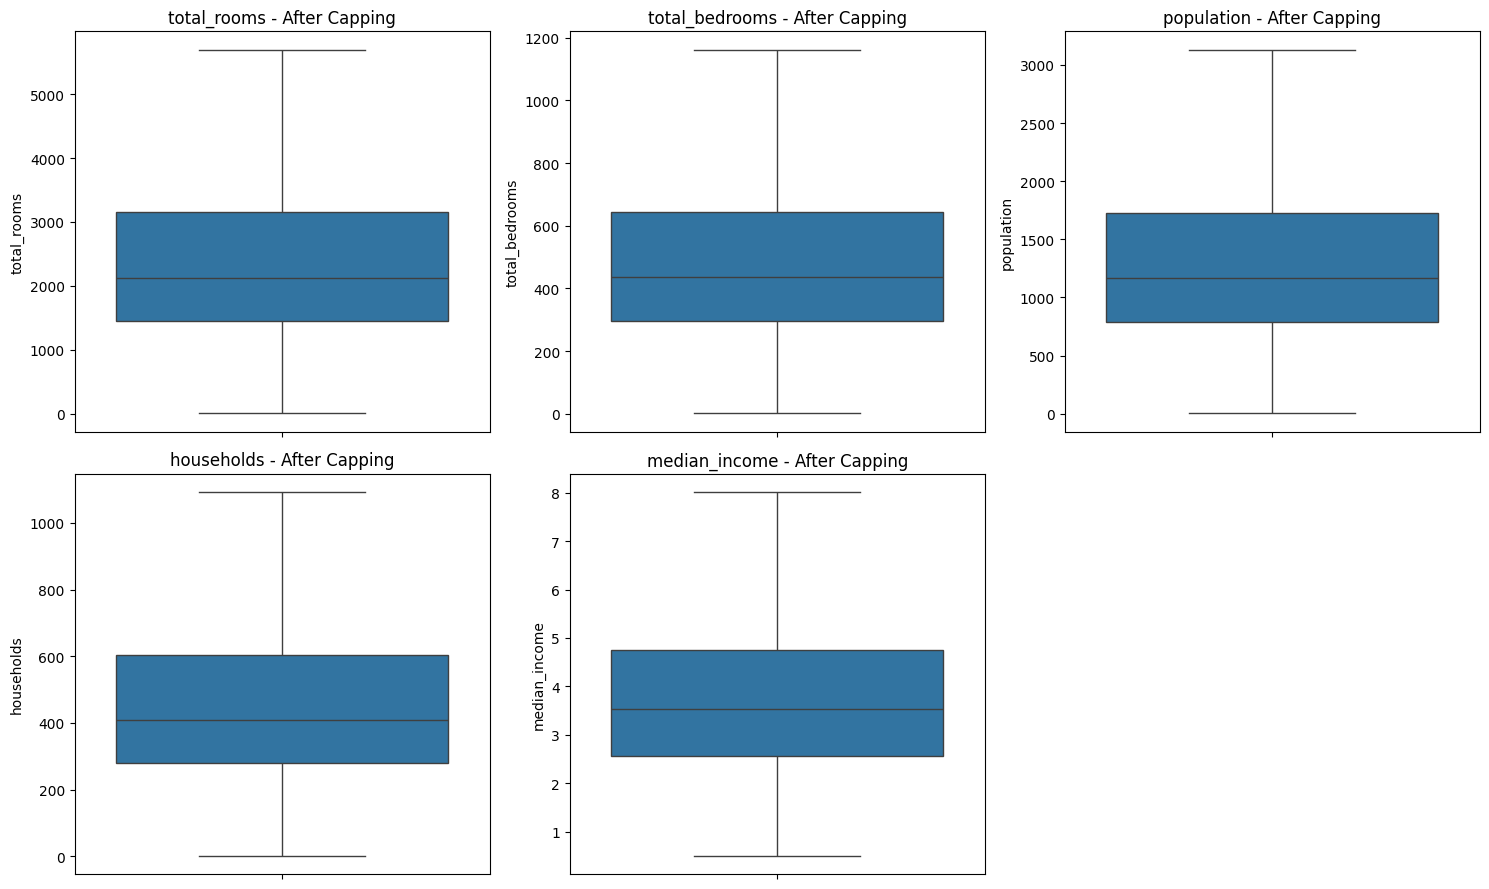

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, column in enumerate(capping_columns):
    sns.boxplot(y=df_eda_capped[column], ax=axes[i])
    axes[i].set_title(f'{column} - After Capping')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## 6. Dataset Limitations Observed During EDA

- `median_house_value` has a maximum recorded value of 500,001. The concentration at this value suggests a ceiling in the dataset. We retain these observations and report this as a dataset limitation rather than changing the target values.
- `housing_median_age` has a maximum value of 52, which also appears to be capped in the dataset.
- `ocean_proximity` contains five categories. `ISLAND` has only five records, so its category is rare.
- Several room, bedroom, population, and household variables are strongly correlated. This may be relevant to the later feature-selection stage.

These observations are documented for the project; they are not additional preprocessing operations in this section.

## 7. Final Model-Ready Preprocessing

### 7.1 Train-Test Split

We separate the target (`median_house_value`) from the predictor variables and split the data into 80% training and 20% testing sets. All fitted preprocessing parameters are learned from the training data only and then applied to the testing data.

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['median_house_value']).copy()
y = df['median_house_value'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (16512, 9)
Testing set: (4128, 9)


### 7.2 Missing-Value Imputation and Capping

The median for `total_bedrooms` and the IQR capping limits are calculated from `X_train` only. The same values and limits are then applied to `X_test` to avoid data leakage.

In [11]:
# Median imputation learned from training data
bedrooms_median_train = X_train['total_bedrooms'].median()

X_train = X_train.copy()
X_test = X_test.copy()

X_train['total_bedrooms'] = X_train['total_bedrooms'].fillna(
    bedrooms_median_train
)
X_test['total_bedrooms'] = X_test['total_bedrooms'].fillna(
    bedrooms_median_train
)

# IQR capping limits learned from training data
final_capping_bounds = {}

for column in capping_columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    final_capping_bounds[column] = (lower, upper)

    X_train[column] = X_train[column].clip(lower=lower, upper=upper)
    X_test[column] = X_test[column].clip(lower=lower, upper=upper)

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())
print("Training and testing capping completed.")

Training missing values: 0
Testing missing values: 0
Training and testing capping completed.


### 7.3 Scaling and Encoding

- **StandardScaler** standardizes numerical predictors by subtracting the training mean and dividing by the training standard deviation.
- **OneHotEncoder** converts the nominal categorical feature `ocean_proximity` into five binary columns.
- The target variable `median_house_value` is kept separate and is not scaled here.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = ['ocean_proximity']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit transformations on training data only
X_train_scaled = preprocessor.fit_transform(X_train)

# Apply the fitted transformations to testing data
X_test_scaled = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_scaled.shape)
print("Testing data after preprocessing:", X_test_scaled.shape)

Training data after preprocessing: (16512, 13)
Testing data after preprocessing: (4128, 13)


## 8. Final Verification

We verify that the train-test split preserves all observations, missing values have been handled, and the transformed feature matrix contains the expected number of columns.

In [13]:
feature_names = preprocessor.get_feature_names_out()

print("Training rows:", X_train_scaled.shape[0])
print("Testing rows:", X_test_scaled.shape[0])

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nNumber of transformed features:", len(feature_names))
print("Transformed feature names:")
for name in feature_names:
    print(name)

Training rows: 16512
Testing rows: 4128
Training missing values: 0
Testing missing values: 0
Training target shape: (16512,)
Testing target shape: (4128,)

Number of transformed features: 13
Transformed feature names:
num__longitude
num__latitude
num__housing_median_age
num__total_rooms
num__total_bedrooms
num__population
num__households
num__median_income
cat__ocean_proximity_<1H OCEAN
cat__ocean_proximity_INLAND
cat__ocean_proximity_ISLAND
cat__ocean_proximity_NEAR BAY
cat__ocean_proximity_NEAR OCEAN


## 9. Preprocessing Summary

| Task | Method | Result |
|---|---|---|
| Missing values | Median imputation | 207 missing `total_bedrooms` values addressed |
| Outlier detection | IQR and Z-Score | Two detection methods compared |
| Outlier treatment | IQR capping | Selected predictor values capped; rows retained |
| Scaling | StandardScaler | Applied to 8 numerical predictors |
| Encoding | OneHotEncoder | `ocean_proximity` converted into 5 binary features |

**Final transformed data:** 16,512 training rows and 4,128 testing rows, with 13 transformed predictor features. The target (`median_house_value`) remains separate.

**Important for the next project stage:** Use `X_train_scaled`, `X_test_scaled`, `y_train`, and `y_test` as the model inputs and target outputs. Do not fit the preprocessor again on the test data.